# SafeBorrow: step by step

**Can my business actually afford this loan?**

How to use this notebook:
- Run the cells **in order, from top to bottom**. Click a cell and press **Shift+Enter**.
- Read the text above each cell first, so you know what it does.
- You need internet for Step 2 the first time (it downloads the data). No account needed.

Our example business: a **rental shop**. We use two years of real daily rental data and treat it as the shop's daily income.

What we'll build:
1. Load the data and turn it into daily income
2. Make features the model can learn from
3. Train a **sales forecaster** that predicts a range (low, typical, high)
4. Check how good the forecaster is
5. **Simulate** 1,000 possible futures and work out the risk of missing a loan repayment
6. Search for the **safe loan size** and the safest repayment schedule
7. Save everything for the demo app (`app.py`)

## Step 1: Import the libraries
If this cell gives a `ModuleNotFoundError`, your notebook is on the wrong kernel. Click **Select Kernel** (top right) and choose `.venv`.

In [49]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
import joblib
from sklearn.datasets import fetch_openml
from sklearn.metrics import mean_absolute_error

plt.rcParams["figure.figsize"] = (12, 4)
print("All libraries loaded")

All libraries loaded


## Step 2: Download the data
This is the **Bike Sharing** dataset: real hourly bike rentals over two years (2011–2012), with holiday and working-day information. The first run downloads it (a few seconds); after that it's saved on your computer.

In [50]:
raw = fetch_openml("Bike_Sharing_Demand", version=2, as_frame=True, parser="liac-arff").frame
print(raw.shape)
raw.head()

(17379, 13)


,season,year,month,hour,holiday,weekday,workingday,weather,temp,feel_temp,humidity,windspeed,count
0,spring,0,1,0,False,6,False,clear,9.84,14.395,0.81,0.0,16
1,spring,0,1,1,False,6,False,clear,9.02,13.635,0.80,0.0,40
2,spring,0,1,2,False,6,False,clear,9.02,13.635,0.80,0.0,32
3,spring,0,1,3,False,6,False,clear,9.84,14.395,0.75,0.0,13
4,spring,0,1,4,False,6,False,clear,9.84,14.395,0.75,0.0,1


## Step 3: Turn hourly rentals into daily income
The data has no date column, only `year`, `month`, `weekday` and `hour`. The rows are in time order, so we rebuild the dates: every time `weekday` changes, a new day has started. (If a whole day were missing, the weekday would jump by 2, and we count that too.)

Then we add up the hours into **one row per day**, and run a check that the rebuilt dates match the weekdays in the data.

In [51]:
df = raw.copy()
df["weekday"] = df["weekday"].astype(int)          # 0 = Sunday ... 6 = Saturday
df["hour"] = df["hour"].astype(int)
df["count"] = df["count"].astype(float)
for col in ["holiday", "workingday"]:
    df[col] = df[col].astype(str).isin(["True", "true", "1"]).astype(int)

# Rebuild the dates: move forward by however many days the weekday jumped
step = (df["weekday"] - df["weekday"].shift()).mod(7).fillna(0)
df["Date"] = pd.Timestamp("2011-01-01") + pd.to_timedelta(step.cumsum(), unit="D")

daily = (df.groupby("Date")
           .agg(rentals=("count", "sum"), weekday=("weekday", "first"),
                holiday=("holiday", "max"), workingday=("workingday", "max"))
           .reset_index())

# Check: pandas counts Monday = 0, the dataset counts Sunday = 0
dates_ok = ((daily["Date"].dt.dayofweek + 1) % 7 == daily["weekday"]).all()
print(f"{len(daily)} days, from {daily['Date'].min().date()} to {daily['Date'].max().date()}")
print("Dates check out:", dates_ok)

731 days, from 2011-01-01 to 2012-12-31
Dates check out: True


/tmp/ipykernel_83510/1031418465.py:18: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  dates_ok = ((daily["Date"].dt.dayofweek + 1) % 7 == daily["weekday"]).all()


Now scale rentals into **GHS of daily income** for a small shop, so that an average day is about **GHS 400**. In your pitch, say clearly that this is real daily demand data scaled to GHS.

Average income per day: GHS 400


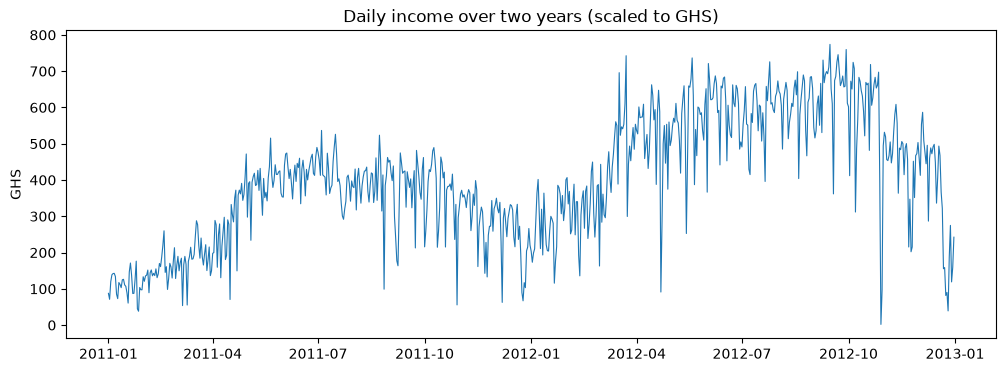

In [52]:
TARGET_AVG = 400   # GHS per day for a typical small business

scale = TARGET_AVG / daily["rentals"].mean()
daily["Sales"] = daily["rentals"] * scale
print("Average income per day: GHS", round(daily["Sales"].mean()))

plt.plot(daily["Date"], daily["Sales"], linewidth=0.8)
plt.title("Daily income over two years (scaled to GHS)")
plt.ylabel("GHS")
plt.show()

Look at the chart: busy summers, quiet winters, and the business growing in its second year. A good forecaster has to learn all of that.

## Step 4: Make features
Features are the facts the model learns from. We only use facts **we know in advance**, because we're forecasting weeks ahead:
- day of week, day of month (payday effects), month, week of year
- holidays and working days
- `year`: which year of the business it is, so the model knows the business has grown

**Why no "yesterday's sales"?** When we forecast a month ahead we won't know yesterday's sales for most of those days. **Why no weather?** We won't know the weather a month ahead either.

In [53]:
START = daily["Date"].min()

def make_features(frame):
    X = pd.DataFrame(index=frame.index)
    X["dayofweek"] = frame["Date"].dt.dayofweek
    X["day"] = frame["Date"].dt.day
    X["month"] = frame["Date"].dt.month
    X["weekofyear"] = frame["Date"].dt.isocalendar().week.astype(int).values
    X["holiday"] = frame["holiday"].astype(int)
    X["workingday"] = frame["workingday"].astype(int)
    X["year"] = frame["Date"].dt.year - START.year
    return X

make_features(daily).tail()

/tmp/ipykernel_83510/3650643238.py:5: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  X["dayofweek"] = frame["Date"].dt.dayofweek


,dayofweek,day,month,weekofyear,holiday,workingday,year
726,3,27,12,52,0,1,1
727,4,28,12,52,0,1,1
728,5,29,12,52,0,0,1
729,6,30,12,52,0,0,1
730,0,31,12,1,0,1,1


## Step 5: Split by time
We train on the older data and test on the **last 12 weeks**, which the model never sees during training.

Never split randomly here. A random split lets the model peek at days surrounding the test days, and the scores come out better than they really are.

In [54]:
TEST_WEEKS = 12
cutoff = daily["Date"].max() - pd.Timedelta(weeks=TEST_WEEKS)

train = daily[daily["Date"] <= cutoff]
test = daily[daily["Date"] > cutoff]

X_train, y_train = make_features(train), train["Sales"]
X_test, y_test = make_features(test), test["Sales"]
print(f"Train: {len(train)} days, up to {cutoff.date()}")
print(f"Test:  {len(test)} days, after that")

Train: 647 days, up to 2012-10-08
Test:  84 days, after that


/tmp/ipykernel_83510/3650643238.py:5: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  X["dayofweek"] = frame["Date"].dt.dayofweek
/tmp/ipykernel_83510/3650643238.py:5: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  X["dayofweek"] = frame["Date"].dt.dayofweek


## Step 6: Train the forecaster (quantile regression)
We train **three** LightGBM models:
- **0.1**: a low estimate (income should be above this about 90% of the time)
- **0.5**: the typical (median) estimate
- **0.9**: a high estimate (income should be below this about 90% of the time)

Together they give a *range* for each day, not just one number.

We train on the **log** of income. That turns "the business grew by 60%" and "winter is half as busy" into simple additions, which trees handle much better. We convert back with `np.expm1` when predicting.

In [55]:
QUANTILES = [0.1, 0.5, 0.9]
models = {}
for q in QUANTILES:
    m = lgb.LGBMRegressor(objective="quantile", alpha=q, n_estimators=300,
                          learning_rate=0.05, num_leaves=15, min_child_samples=10, verbose=-1)
    m.fit(X_train, np.log1p(y_train))
    models[q] = m
    print(f"Trained the {q} model")

Trained the 0.1 model
Trained the 0.5 model
Trained the 0.9 model


## Step 7: How good is the forecaster?
Three numbers to put in your pitch:
- **MAE**: on average, how many GHS the typical forecast is off by.
- **Baseline MAE**: the error of a simple guess (the average of the 4 weeks before the test period, by day of week). The model should beat this. If it doesn't, the ML isn't adding anything.
- **Coverage**: how often real income landed between the low and high estimates. It should be close to **80%**. Much lower means the model is overconfident.

In [56]:
pred = {q: np.expm1(models[q].predict(X_test)) for q in QUANTILES}

mae = mean_absolute_error(y_test, pred[0.5])

recent = train[train["Date"] > cutoff - pd.Timedelta(weeks=4)]
dow_avg = recent.groupby(recent["Date"].dt.dayofweek)["Sales"].mean()
baseline = test["Date"].dt.dayofweek.map(dow_avg).values
baseline_mae = mean_absolute_error(y_test, baseline)

coverage = ((y_test >= pred[0.1]) & (y_test <= pred[0.9])).mean()

print(f"Model MAE:    GHS {mae:.0f}  ({mae / y_test.mean():.0%} of an average day)")
print(f"Baseline MAE: GHS {baseline_mae:.0f}")
print(f"Coverage:     {coverage:.0%}  (target is about 80%)")

Model MAE:    GHS 172  (38% of an average day)
Baseline MAE: GHS 206
Coverage:     67%  (target is about 80%)


/tmp/ipykernel_83510/3843859451.py:6: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  dow_avg = recent.groupby(recent["Date"].dt.dayofweek)["Sales"].mean()
/tmp/ipykernel_83510/3843859451.py:7: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  baseline = test["Date"].dt.dayofweek.map(dow_avg).values


Plot the test weeks: the real income, the typical forecast, and the shaded range between low and high.

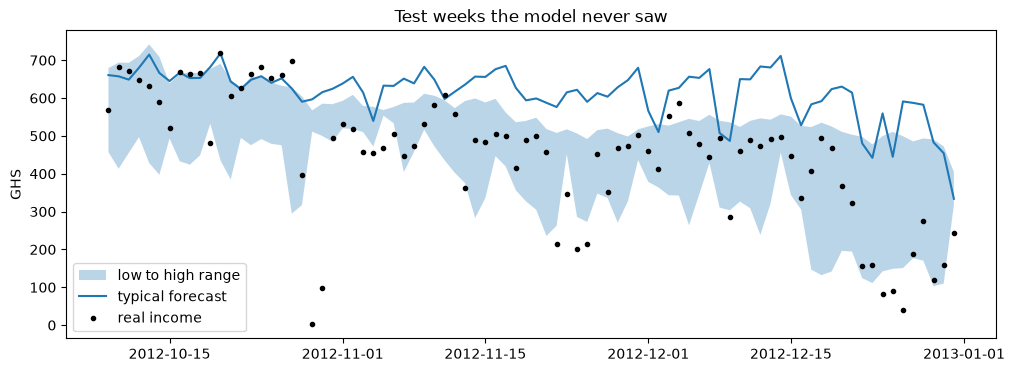

In [57]:
plt.fill_between(test["Date"], pred[0.1], pred[0.9], alpha=0.3, label="low to high range")
plt.plot(test["Date"], pred[0.5], label="typical forecast")
plt.plot(test["Date"], y_test, "k.", label="real income")
plt.title("Test weeks the model never saw")
plt.ylabel("GHS")
plt.legend()
plt.show()

## Step 8: Collect the model's real mistakes
To simulate realistic futures, we need to know how wrong the forecast tends to be. For each test day we store **real income ÷ forecast**: 1.0 means spot on, 0.8 means income was 20% lower than forecast.

We keep these in **blocks of 7 days in a row** (one week). Bad days often come in runs (a rainy week, for example), so sampling whole weeks keeps that realism. Sampling single days at random would make the risk look lower than it is.

In [58]:
BLOCK = 7
ratios = y_test.values / pred[0.5]
blocks = np.array([ratios[i:i + BLOCK] for i in range(len(ratios) - BLOCK + 1)])

print(f"{len(blocks)} blocks of {BLOCK} days")
print("Typical ratio:", np.round(np.percentile(blocks, [10, 50, 90]), 2), "(10th, 50th, 90th percentile)")

78 blocks of 7 days
Typical ratio: [0.33 0.74 1.01] (10th, 50th, 90th percentile)


## Step 9: Simulate 1,000 possible futures
1. Pick **when the loan starts**. Seasons matter a lot for this business: a loan taken in a quiet month is much riskier than the same loan in a busy month. Try changing `START_MONTH` later and re-running Steps 9–12.
2. Forecast the typical income for each day of the loan period (for the year after our data, at the business's latest size).
3. Make 1,000 copies and multiply each by randomly picked weeks of real mistakes.

Every row of `sales_sims` is one possible future.

/tmp/ipykernel_83510/3317308659.py:4: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  "workingday": (dates.dayofweek < 5).astype(int)})
/tmp/ipykernel_83510/3650643238.py:5: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  X["dayofweek"] = frame["Date"].dt.dayofweek


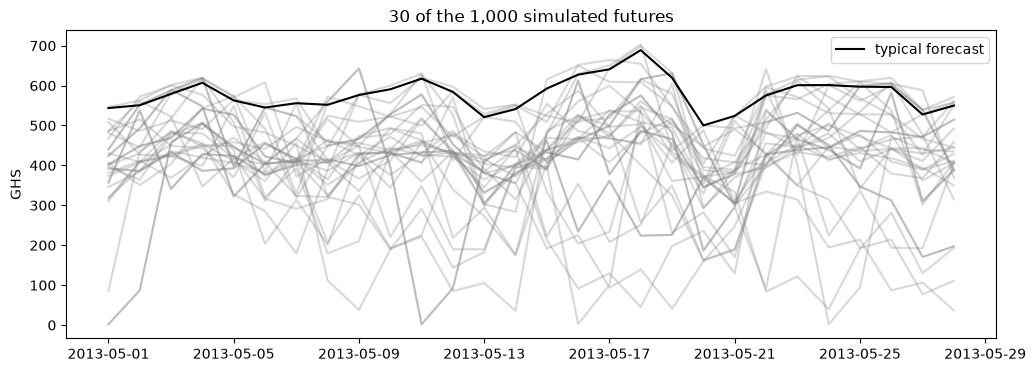

In [59]:
def forecast_future(start_date, n_days):
    dates = pd.date_range(start_date, periods=n_days, freq="D")
    fut = pd.DataFrame({"Date": dates, "holiday": 0,
                        "workingday": (dates.dayofweek < 5).astype(int)})
    return dates, np.expm1(models[0.5].predict(make_features(fut)))


def simulate_sales(median, n_sims=1000, seed=0):
    rng = np.random.default_rng(seed)
    n_blocks = int(np.ceil(len(median) / BLOCK))
    picks = rng.integers(0, len(blocks), size=(n_sims, n_blocks))
    r = blocks[picks].reshape(n_sims, -1)[:, :len(median)]
    return median * r


TERM_WEEKS = 4
START_MONTH = 5      # 1 = January ... 12 = December
start = pd.Timestamp(year=daily["Date"].max().year + 1, month=START_MONTH, day=1)
dates, median = forecast_future(start, TERM_WEEKS * 7)
sales_sims = simulate_sales(median)

for i in range(30):
    plt.plot(dates, sales_sims[i], color="grey", alpha=0.3)
plt.plot(dates, median, color="black", label="typical forecast")
plt.title("30 of the 1,000 simulated futures")
plt.ylabel("GHS")
plt.legend()
plt.show()

## Step 10: Turn a loan offer into a repayment plan
- **Total to repay** = amount × (1 + monthly interest × months).
- Three schedules: **daily**, **weekly** (every 7th day), or **one lump sum at the end**.

We assume the loan money is spent straight away (on equipment or stock, for example), so it isn't sitting in the cash box to pay itself back.

In [60]:
def repayment_plan(amount, monthly_rate, term_weeks, schedule):
    n_days = term_weeks * 7
    total = amount * (1 + monthly_rate * n_days / 30)
    days = np.arange(1, n_days + 1)
    if schedule == "daily":
        due = days
    elif schedule == "weekly":
        due = days[days % 7 == 0]
    else:                                   # "end": one payment on the last day
        due = np.array([n_days])
    plan = np.zeros(n_days)
    plan[due - 1] = total / len(due)
    return plan, total


plan, total = repayment_plan(1000, 0.10, TERM_WEEKS, "weekly")
print(f"Borrow GHS 1000 at 10% a month for {TERM_WEEKS} weeks: repay GHS {total:.0f} in total")
print("Payments on days:", np.nonzero(plan)[0] + 1)

Borrow GHS 1000 at 10% a month for 4 weeks: repay GHS 1093 in total
Payments on days: [ 7 14 21 28]


## Step 11: Risk of missing a repayment
For every simulated future, track the cash day by day:
- **plus** profit (income × profit margin)
- **minus** daily costs (rent, transport, family spending)
- **minus** any repayment due that day

If the cash is below zero after a repayment day, that future **missed a payment**. The risk is the share of the 1,000 futures that missed at least once.

**Income isn't profit**, which is why the profit margin matters so much.

Risk of missing at least one payment: 18%


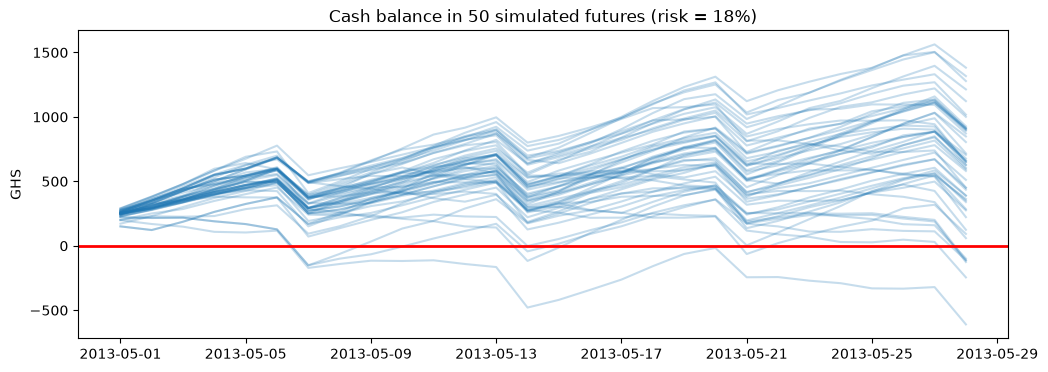

In [61]:
def missed_payment_risk(sales_sims, plan, margin, daily_costs, start_cash):
    profit = sales_sims * margin - daily_costs
    cash = start_cash + profit.cumsum(axis=1) - plan.cumsum()
    due = plan > 0
    missed = (cash[:, due] < 0).any(axis=1)
    return missed.mean(), cash


MARGIN = 0.25        # 25% profit on each cedi of income
DAILY_COSTS = 50     # GHS per day
START_CASH = 200     # GHS in the cash box today
RATE = 0.10          # 10% interest per month

risk, cash = missed_payment_risk(sales_sims, plan, MARGIN, DAILY_COSTS, START_CASH)
print(f"Risk of missing at least one payment: {risk:.0%}")

for i in range(50):
    plt.plot(dates, cash[i], color="tab:blue", alpha=0.25)
plt.axhline(0, color="red", linewidth=2)
plt.title(f"Cash balance in 50 simulated futures (risk = {risk:.0%})")
plt.ylabel("GHS")
plt.show()

## Step 12: Find the safe loan size
Try every loan size from GHS 50 to 2,000 under each schedule. Every option is tested on **the same 1,000 futures**, so the comparison is fair.

The **safe loan** is the biggest amount that keeps the risk at or under 10%.

 daily: safe loan up to GHS 600
   end: safe loan up to GHS 1100
weekly: safe loan up to GHS 650


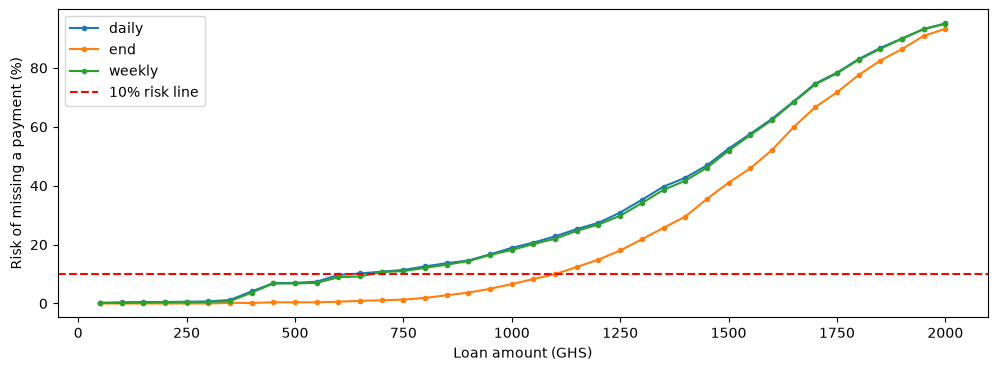

In [62]:
SAFE_RISK = 0.10
amounts = np.arange(50, 2001, 50)

rows = []
for schedule in ["daily", "weekly", "end"]:
    for a in amounts:
        plan, total = repayment_plan(a, RATE, TERM_WEEKS, schedule)
        risk, _ = missed_payment_risk(sales_sims, plan, MARGIN, DAILY_COSTS, START_CASH)
        rows.append({"schedule": schedule, "amount": a, "risk": risk})
results = pd.DataFrame(rows)

for schedule, g in results.groupby("schedule"):
    plt.plot(g["amount"], g["risk"] * 100, marker=".", label=schedule)
    ok = g[g["risk"] <= SAFE_RISK]
    safe = ok["amount"].max() if len(ok) else 0
    print(f"{schedule:>6}: safe loan up to GHS {safe}")
plt.axhline(SAFE_RISK * 100, color="red", linestyle="--", label="10% risk line")
plt.xlabel("Loan amount (GHS)")
plt.ylabel("Risk of missing a payment (%)")
plt.legend()
plt.show()

## Step 13: Save everything for the app
This writes `safeborrow_model.joblib`. The Streamlit app (`app.py`) loads it, so **run this cell before you start the app**.

In [65]:
joblib.dump({
    "models": models,
    "blocks": blocks,
    "block_size": BLOCK,
    "start": START,
    "forecast_year": daily["Date"].max().year + 1,
}, "safeborrow_model.joblib")
print("Saved safeborrow_model.joblib. Now run:  streamlit run app.py")

Saved safeborrow_model.joblib. Now run:  streamlit run app.py


## Ideas if you have time left
- Let users **upload their own sales** as a CSV instead of using the example business.
- Add **Ghana public holidays** and **market days** as features.
- Use a **weather forecast** for the first week of the loan (the dataset has weather columns you could train on).
- Model the loan **boosting sales** (new equipment means more to rent out): multiply future income by a small uplift.